<a href="https://colab.research.google.com/github/eunnypark/Keplers-Third-Law/blob/main/%EC%BC%80%ED%94%8C%EB%9F%AC%EC%A0%9C3%EB%B2%95%EC%B9%99.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. 행성 데이터 입력

import numpy as np
import matplotlib.pyplot as plt

planets = np.array(["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", "Uranus", "Neptune"])     # 태양계 행성 이름
a = np.array([0.3870993, 0.723336, 1.000003, 1.52371, 5.2029, 9.537, 19.189, 30.0699])                  # 행성의 공전 궤도 장반경 (AU 단위)
T = np.array([0.2408467, 0.61519726, 1.0000174, 1.8808158, 11.862615, 29.447498, 84.016846, 164.79132]) # 행성의 공전 주기 (년)

# 케플러 제3법칙을 T^2=k*a^3 꼴로 만들기 위해 원래 데이터를 새로운 형태로 변환 (비선형 관계를 선형 관계처럼 표현)
X = a ** 3
Y = T ** 2

# 데이터 정규화: X와 Y에 동일한 기준값 사용
# 태양계 행성의 경우 AU와 년 단위를 사용하면 비례상수 k는 대략 1 -> X의 최댓값으로 두 배열을 똑같이 나누면 두 배열 모두 대체로 0~1 사이 값으로 조정
scale = np.max(X)
X_scaled = X / scale
Y_scaled = Y / scale

상관계수: 0.9999999979310854


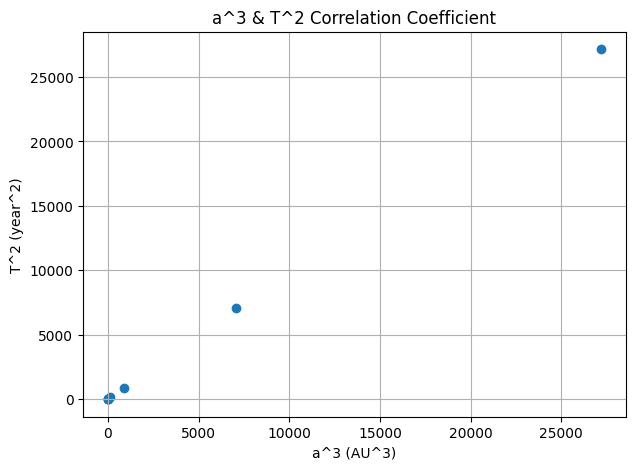

In [2]:
# 2. 상관계수 계산

def correlation_coefficient(x, y):  # 상관계수 계산 함수 정의

    mean_x, mean_y = np.mean(x), np.mean(y) # 각 데이터의 평균 계산
    dx, dy = x - mean_x, y - mean_y         # 평균과 각 데이터의 차이 계산

    cov = np.sum(dx * dy)/len(x) # 공분산

    std_x = np.sqrt(np.sum(dx**2) / len(x)) # x 표준편차
    std_y = np.sqrt(np.sum(dy**2) / len(y)) # y 표준편차
    std_xy = std_x * std_y  # 표준편차끼리의 곱

    return cov / std_xy

r = correlation_coefficient(X, Y) # 상관계수 계산 (상관계수가 높음 != 인과관계)
print("상관계수:", r)

# 산점도
plt.figure(figsize=(7, 5))
plt.scatter(X, Y)
plt.xlabel("a^3 (AU^3)")
plt.ylabel("T^2 (year^2)")
plt.title("a^3 & T^2 Correlation Coefficient")
plt.grid()
plt.show()


In [3]:
# 3. 손실함수 구현

def mse_loss(k, x, y):  # MSE 손실함수. k는 우리가 설정한 비례상수, x는 입력 데이터, y는 실제
    predictions = k * x  # 현재 k를 이용한 예측값
    errors = predictions - y  # 실제값과 예측값의 차이
    return np.mean(errors ** 2) # 평균제곱오차 반환

In [4]:
# 4. 경사하강법 구현

def gradient_descent(x, y, learning_rate, epochs):  # x: 입력 데이터, y: 실제 데이터, learning_rate: 학습률, epochs: 반복횟수

    k = 0.0 # 비례상수의 초기값 설정 (최적의 k값 모름 -> 임의의 값에서 시작)

    loss_history = [] # 경사하강법 반복 과정에서의 손실함수 기록

    for epoch in range(epochs):   # 지정된 횟수만큼 반복

        predictions = k * x     # 현재 k로 예측값 계산

        gradient = 2 * np.mean(x * (predictions - y)) # 손실함수의 기울기(미분값) 계산
        k = k - learning_rate * gradient        # 경사하강법으로 k 갱신

        loss_history.append(mse_loss(k, x, y))  # 현재 손실함수 값 저장

    return k, loss_history

학습률: 0.05
추정한 k: 0.99760171
최종 손실함수: 0.0000001931
학습률: 0.1
추정한 k: 0.99880113
최종 손실함수: 0.0000000005
학습률: 0.3
추정한 k: 0.99880245
최종 손실함수: 0.0000000005
학습률: 0.5
추정한 k: 0.99880245
최종 손실함수: 0.0000000005


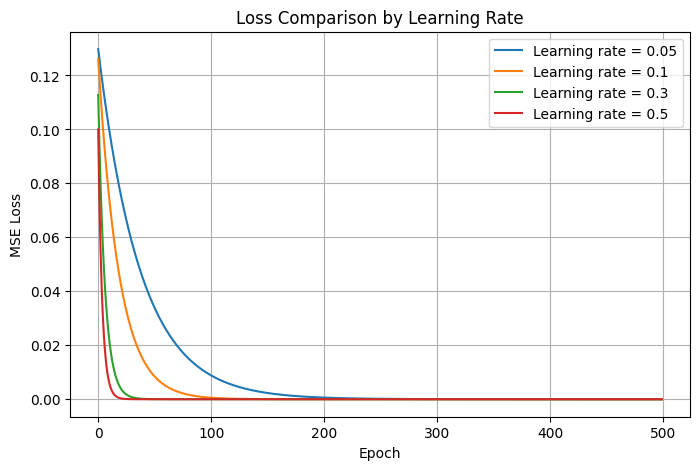

In [5]:
# 5. 학습률에 따른 수렴 비교

learning_rates = [0.05, 0.1, 0.3, 0.5] # 서로 다른 학습률 설정 (비교용)
results = {}  # 실험 결과를 저장할 딕셔너리

for lr in learning_rates: # 각 학습률로 경사하강법 실행

    k, losses = gradient_descent(X_scaled, Y_scaled, learning_rate=lr, epochs=500)

    results[lr] = (k, losses) # 각 학습률에 따른 추정값과 손실함수의 변화 보관

    print(f"학습률: {lr}")
    print(f"추정한 k: {k:.8f}")
    print(f"최종 손실함수: {losses[-1]:.10f}")


plt.figure(figsize=(8, 5))  # 손실함수 변화 그래프

for lr in learning_rates:
    k, losses = results[lr]
    plt.plot(losses, label=f"Learning rate = {lr}")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Loss Comparison by Learning Rate")
plt.legend()
plt.grid()
plt.show()


원본 데이터의 추정값: 0.9988024489074222
잡음 데이터의 추정값: 0.942003615172759
원본 데이터의 손실: 5.425511849507891e-10
잡음 데이터의 손실: 6.608369655909573e-05


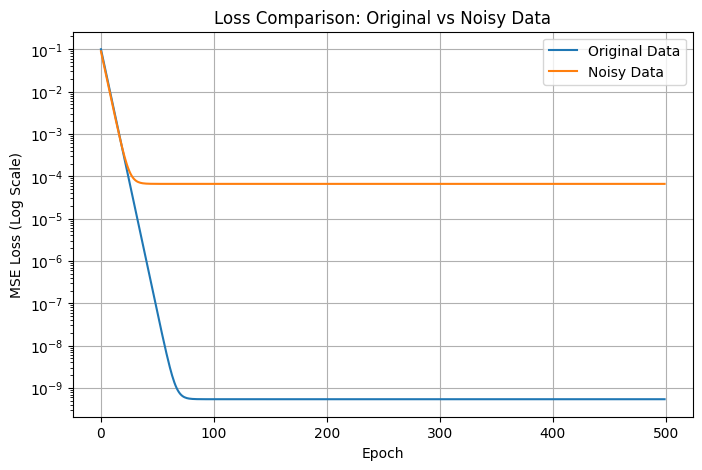

In [6]:
# 6. 데이터에 오차가 섞이면 경사하강법이 추정하는 비례상수 k가 얼마나 달라지는지 확인
# (실제 행성 관측 오차를 재현X, 알고리즘이 데이터 오차에 얼마나 민감한지 확인하기 위한 실험)

rng = np.random.default_rng(42)           # 무작위 난수 생성기. 같은 시드 -> 항상 동일한 난수 배열

noise = rng.normal(0, 0.1, size=len(T))  # 정규분포를 따르는 무작위 오차를 생성. 평균0, 표준편차0.1.

T_noisy = T * (1 + noise)   # 공전 주기에 10% 수준의 오차 추가
Y_noisy = T_noisy ** 2      # 잡음이 추가된 공전 주기 제곱
Y_noisy_scaled = Y_noisy / scale  # 동일한 기준값으로 정규화

# 원본 데이터와 잡음 데이터 각각 학습
k_original, loss_original = gradient_descent(X_scaled, Y_scaled, 0.5, 500)
k_noisy, loss_noisy = gradient_descent(X_scaled, Y_noisy_scaled, 0.5, 500)

# 결과 출력
print("원본 데이터의 추정값:", k_original)
print("잡음 데이터의 추정값:", k_noisy)

print("원본 데이터의 손실:", loss_original[-1])
print("잡음 데이터의 손실:", loss_noisy[-1])

# 비교 그래프
plt.figure(figsize=(8, 5))

plt.plot(loss_original, label="Original Data")
plt.plot(loss_noisy, label="Noisy Data")

plt.xlabel("Epoch")
plt.yscale("log")  # =일반 스케일에서는 눈으로 그래프 차이를 볼 수 없어 y축을 로그 스케일로 변경.
plt.ylabel("MSE Loss (Log Scale)")
plt.title("Loss Comparison: Original vs Noisy Data")
plt.legend()
plt.grid()
plt.show()


케플러 제3법칙의 이론값: 1.0
경사하강법 추정값: 0.9988024489074222
최소제곱법 계산값: 0.9988024489074224
두 방법으로 계산한 값의 차이: 2.220446049250313e-16


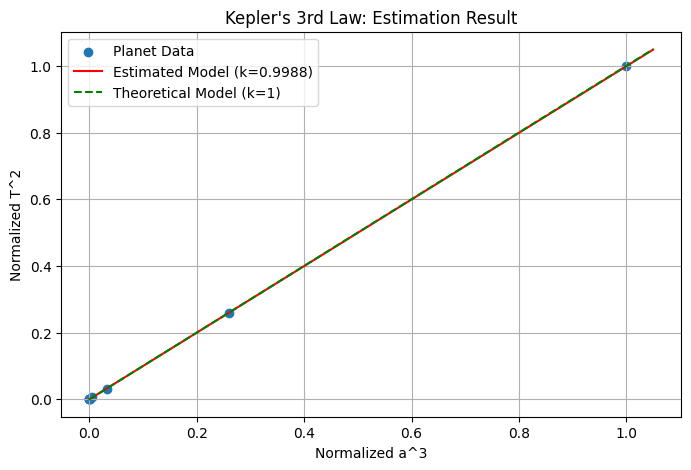

In [7]:
# 7. 결과 시각화 & 검산

k_exact = np.sum(X_scaled * Y_scaled) / np.sum(X_scaled ** 2) # 최소제곱법으로 계산한 최적 비례상수

# 이론값과 추정값 비교
print("케플러 제3법칙의 이론값:", 1.0)  # 정확히 1은 아니고, 1에 근사
print("경사하강법 추정값:", k_original)
print("최소제곱법 계산값:", k_exact)

# 경사하강법과 최소제곱법의 차이
error = abs(k_original - k_exact)
print("두 방법으로 계산한 값의 차이:", error)

# 실제 데이터와 예측 직선 비교
plt.figure(figsize=(8, 5))

plt.scatter(X_scaled, Y_scaled, label="Planet Data") # 실제 행성 데이터

# 예측 직선 작성
x_line = np.linspace(0, 1.05, 100)  # 직선 만들기용 x값 100개 설정
y_line = k_original * x_line        # 경사하강법으로 추정한 y (직선)

plt.plot(x_line, y_line, color="red", label=f"Estimated Model (k={k_original:.4f})")  # 경사하강법으로 추정한 k로 그린 그래프
plt.plot(x_line, x_line, color="green", linestyle="--", label="Theoretical Model (k=1)")  # k=1일 때의 (이론값) 그래프

plt.xlabel("Normalized a^3")
plt.ylabel("Normalized T^2")
plt.title("Kepler's 3rd Law: Estimation Result")
plt.legend()
plt.grid()
plt.show()
